# DL089 完整实验回放
融合与受控视觉问答：5方法、3种子、8测试域。无预训练语言模型。本Notebook真实重训到notebook_run，不覆盖发行outputs。CPU NumPy、合成数据、无需网络。

In [1]:
from pathlib import Path
import json, numpy as np
import experiment as exp
original_root = exp.ROOT
print("NumPy", np.__version__)

NumPy 2.3.5


## 数据与输入边界
先检查shape，再运行优化。评价真值不能作为预测输入。

In [2]:
d = exp.make_data(96, 8901)
print({k: v.shape for k, v in d.items()})
print("visual tokens", exp.tokenize(d["images"]).shape)
for m in exp.METHODS:
    print(m, sum(v.size for v in exp.initial(m, 11).values()))

{'images': (96, 8, 8, 3), 'q': (96, 2), 'h': (96, 2), 'y': (96,), 'colors': (96, 2), 'side': (96,), 'hint': (96,)}
visual tokens (96, 2, 5)
text_only 114
image_only 210
concat_biased 274
attention_biased 268
attention_random_hint 268


## 手算与梯度核验
有限差分支持局部导数；它不替代数据切分和研究设计审查。

In [3]:
a = exp.softmax(np.array([[0., np.sqrt(2)]]))
print("attention weights and readout", a, a @ np.eye(2))
print("gradient check", exp.gradient_check())
print("image-only Bayes expectation", 0.5*1 + 0.5*0.5)

attention weights and readout [[0.19557032 0.80442968]] [[0.19557032 0.80442968]]
gradient check {'w1': np.float64(3.69217503792818e-12), 'b1': np.float64(1.9665588602002515e-12), 'w2': np.float64(4.1621844859562884e-12), 'b2': np.float64(5.526690216584029e-13), 'wq': np.float64(1.873164384019743e-12), 'wk': np.float64(7.084083591003126e-12), 'wv': np.float64(9.102604087152244e-12)}
image-only Bayes expectation 0.75


## 从随机初始化完整重训
固定全部方法、种子与更新步数。新结果写入独立子目录。

In [4]:
run_root = original_root / "notebook_run"
run_root.mkdir(exist_ok=True)
exp.ROOT = run_root
try:
    result = exp.main()
finally:
    exp.ROOT = original_root

{
  "mean_accuracy": {
    "text_only": {
      "clean": 0.9333333333333332,
      "conflict_hint": 0.0,
      "blank_hint": 0.5,
      "target_occluded": 0.9333333333333332,
      "target_occluded_blank_hint": 0.5,
      "other_occluded": 0.9333333333333332,
      "image_blank": 0.9333333333333332,
      "question_flip": 0.49583333333333335
    },
    "image_only": {
      "clean": 0.7395833333333334,
      "conflict_hint": 0.7395833333333334,
      "blank_hint": 0.7395833333333334,
      "target_occluded": 0.5,
      "target_occluded_blank_hint": 0.5,
      "other_occluded": 1.0,
      "image_blank": 0.5,
      "question_flip": 0.7604166666666666
    },
    "concat_biased": {
      "clean": 0.9972222222222222,
      "conflict_hint": 0.9770833333333333,
      "blank_hint": 1.0,
      "target_occluded": 0.9090277777777778,
      "target_occluded_blank_hint": 0.5013888888888889,
      "other_occluded": 1.0,
      "image_blank": 0.9333333333333332,
      "question_flip": 0.98333333333333

## 从本次运行重算结果
不读取发行汇总表冒充Notebook运行。

In [5]:
for method in exp.METHODS:
    print(method, {domain: float(np.mean([r["accuracy"] for r in result["records"] if r["method"]==method and r["domain"]==domain])) for domain in exp.DOMAINS})

text_only {'clean': 0.9333333333333332, 'conflict_hint': 0.0, 'blank_hint': 0.5, 'target_occluded': 0.9333333333333332, 'target_occluded_blank_hint': 0.5, 'other_occluded': 0.9333333333333332, 'image_blank': 0.9333333333333332, 'question_flip': 0.49583333333333335}
image_only {'clean': 0.7395833333333334, 'conflict_hint': 0.7395833333333334, 'blank_hint': 0.7395833333333334, 'target_occluded': 0.5, 'target_occluded_blank_hint': 0.5, 'other_occluded': 1.0, 'image_blank': 0.5, 'question_flip': 0.7604166666666666}
concat_biased {'clean': 0.9972222222222222, 'conflict_hint': 0.9770833333333333, 'blank_hint': 1.0, 'target_occluded': 0.9090277777777778, 'target_occluded_blank_hint': 0.5013888888888889, 'other_occluded': 1.0, 'image_blank': 0.9333333333333332, 'question_flip': 0.9833333333333333}
attention_biased {'clean': 1.0, 'conflict_hint': 1.0, 'blank_hint': 1.0, 'target_occluded': 0.7374999999999999, 'target_occluded_blank_hint': 0.4993055555555556, 'other_occluded': 1.0, 'image_blank':

## 对研究假设做检查

In [6]:
flipped = exp.intervene(d, "question_flip")
print("original labels", d["y"][:8])
print("counterfactual labels", flipped["y"][:8])
print("checkpoint reload error", result["reload_max_error"])
print("Note: other-side masking itself reveals the selected side.")

original labels [0 0 0 0 1 1 1 0]
counterfactual labels [1 1 1 1 1 0 0 1]
checkpoint reload error 0.0
Note: other-side masking itself reveals the selected side.


## 全部自动测试
测试失败会中止回放，而不是继续绘制看起来成功的结果。

In [7]:
import unittest
suite = unittest.defaultTestLoader.discover(str(original_root), pattern="test_experiment.py")
check = unittest.TextTestRunner(verbosity=2).run(suite)
if not check.wasSuccessful():
    raise RuntimeError("test failure")

test_attention_probability (test_experiment.TestFusion.test_attention_probability) ... 

ok


test_balanced_data (test_experiment.TestFusion.test_balanced_data) ... 

ok


test_blank_hint (test_experiment.TestFusion.test_blank_hint) ... 

...

test_training_updates_attention (test_experiment.TestFusion.test_training_updates_attention) ... 

ok


test_true_labels (test_experiment.TestFusion.test_true_labels) ... 

ok


----------------------------------------------------------------------
Ran 18 tests in 0.091s

OK


## 显示本次真实训练图表
PNG直接嵌入输出，离线打开Notebook也可看图。

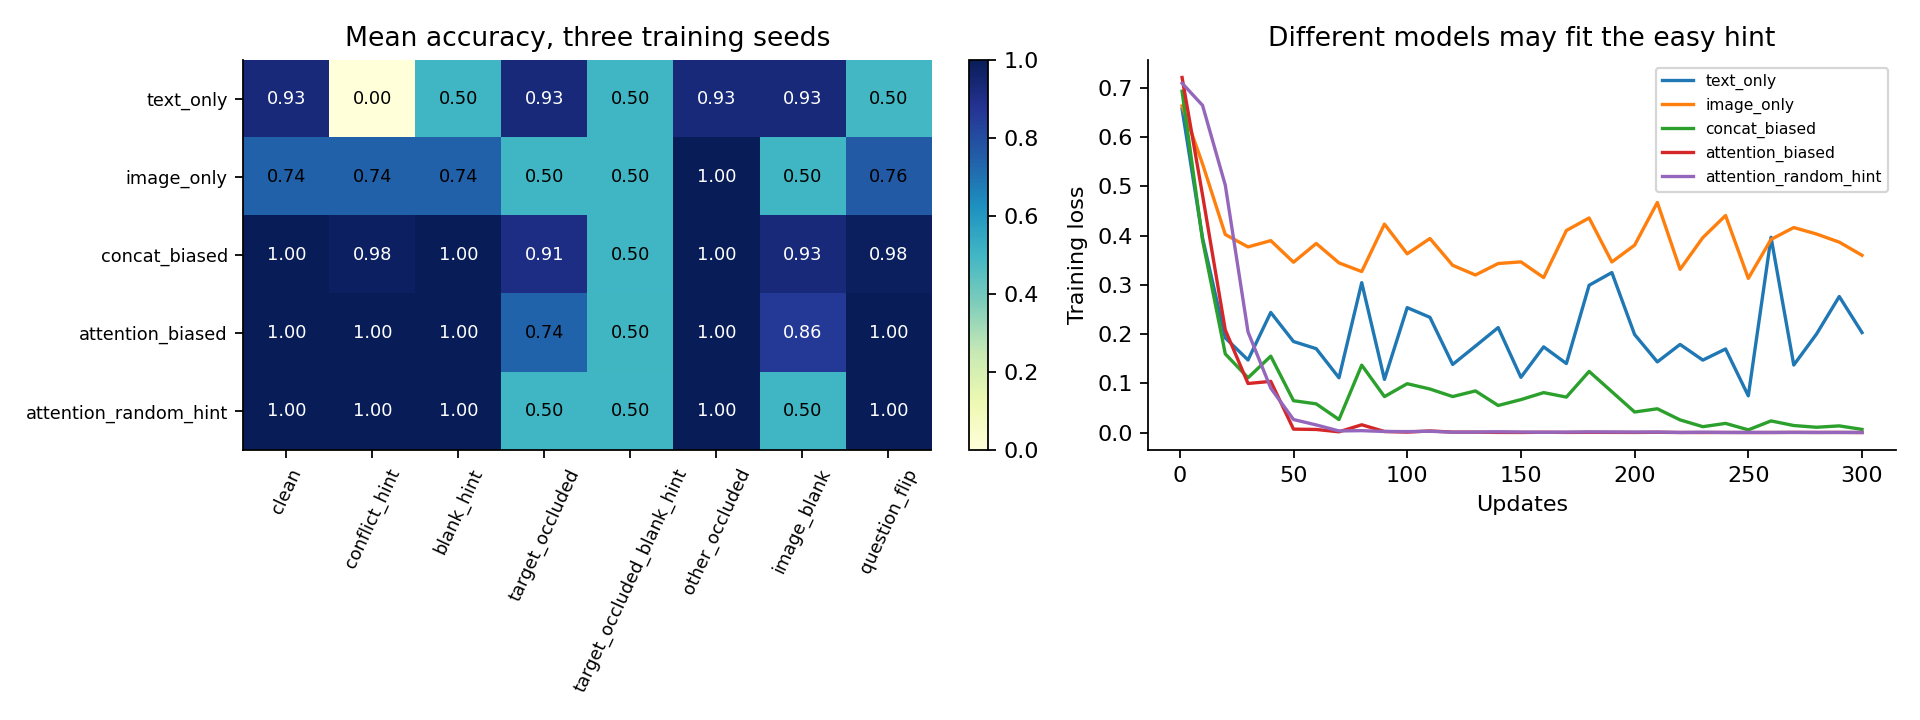

In [8]:
from IPython.display import display, Image
display(Image(filename=str(run_root / "figures" / "03_accuracy_training.png")))

## 写下结论
记录一个受证据支持的发现、一个不支持的预设、一个不能外推的能力。对照lecture.md、lab.md和answers.md，不把教学小模型称为大型VLM复现。